# Prédiction des impayés télécom (`default_risk`) – exploration et entraînement

Jeu de données : **Telecom Credit Scoring Data (Nigeria)**, Hugging Face `electricsheepafrica/africa-synth-telecom-telecom-credit-scoring-data-nigeria` (500 000 lignes, 15 colonnes).

Le notebook réutilise le code du dépôt (`src/data.py`, `src/train.py`) et les paramètres de `params.yaml`, afin que l'exploration et le pipeline de production utilisent exactement les mêmes traitements.

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.config import load_params
from src.data import load_data
from src.train import train, encode_target

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
p = load_params()
p["data"]

{'hf_dataset': 'electricsheepafrica/africa-synth-telecom-telecom-credit-scoring-data-nigeria',
 'raw_path': 'data/raw/telecom.csv',
 'target': 'default_risk',
 'positive_labels': ['high'],
 'drop_columns': ['customer_id', 'phone_number', 'assessment_date'],
 'test_size': 0.2,
 'seed': 42}

## 1. Chargement et contrôle qualité

In [2]:
df = load_data(p)          # télécharge si besoin, puis contrôles de qualité (src/data.py)
print(df.shape)
df.head()

(500000, 15)


,customer_id,phone_number,operator,assessment_date,credit_score,credit_rating,tenure_months,avg_monthly_spend_ngn,recharge_frequency_per_month,payment_consistency_score,late_payment_count,account_type,loan_eligibility,max_loan_amount_ngn,default_risk
0,CUST7884214,2348188064475,9mobile,2025-09-30,766,good,47,38033.69,19,0.61,1,prepaid,True,62311.73,low
1,CUST9262918,2347037995775,MTN,2025-09-30,508,fair,51,4681.59,6,0.60,1,prepaid,False,0.00,low
2,CUST2670942,2348177270309,9mobile,2025-09-30,1000,excellent,114,37461.29,24,0.12,2,prepaid,True,47919.34,medium
3,CUST3837926,2348059892823,Glo,2025-09-30,1000,excellent,118,43504.04,29,0.78,2,prepaid,True,104373.86,low
4,CUST1683850,2348104277310,MTN,2025-09-30,945,excellent,105,41622.46,11,0.48,1,postpaid,True,41723.86,low


In [3]:
pd.DataFrame({"type": df.dtypes.astype(str),
              "valeurs manquantes": df.isna().sum(),
              "valeurs distinctes": df.nunique()})

,type,valeurs manquantes,valeurs distinctes
customer_id,str,0,486339
phone_number,int64,0,499580
operator,str,0,4
assessment_date,str,0,1
credit_score,int64,0,701
credit_rating,str,0,4
tenure_months,int64,0,120
avg_monthly_spend_ngn,float64,0,475710
recharge_frequency_per_month,int64,0,30
payment_consistency_score,float64,0,101


In [4]:
print("Doublons :", df.duplicated().sum())
print("Dates d'évaluation distinctes :", df["assessment_date"].unique())
df.describe().T.round(2)

Doublons : 0
Dates d'évaluation distinctes : <StringArray>
['2025-09-30']
Length: 1, dtype: str


,count,mean,std,min,25%,50%,75%,max
phone_number,500000.0,2.348157e+12,6.636477e+08,2.347010e+12,2.348038e+12,2.348117e+12,2.349013e+12,2.349100e+12
credit_score,500000.0,7.531000e+02,1.946300e+02,3.000000e+02,6.080000e+02,7.690000e+02,9.310000e+02,1.000000e+03
tenure_months,500000.0,6.052000e+01,3.460000e+01,1.000000e+00,3.100000e+01,6.000000e+01,9.000000e+01,1.200000e+02
avg_monthly_spend_ngn,500000.0,2.523979e+04,1.428784e+04,5.000500e+02,1.283660e+04,2.522636e+04,3.760182e+04,4.999993e+04
recharge_frequency_per_month,500000.0,1.548000e+01,8.660000e+00,1.000000e+00,8.000000e+00,1.500000e+01,2.300000e+01,3.000000e+01
payment_consistency_score,500000.0,5.000000e-01,2.900000e-01,0.000000e+00,2.500000e-01,5.000000e-01,7.500000e-01,1.000000e+00
late_payment_count,500000.0,2.240000e+00,2.640000e+00,0.000000e+00,0.000000e+00,1.000000e+00,2.000000e+00,1.000000e+01
max_loan_amount_ngn,500000.0,3.700195e+04,3.668364e+04,0.000000e+00,0.000000e+00,3.025449e+04,6.222840e+04,1.495883e+05


## 2. Variable cible

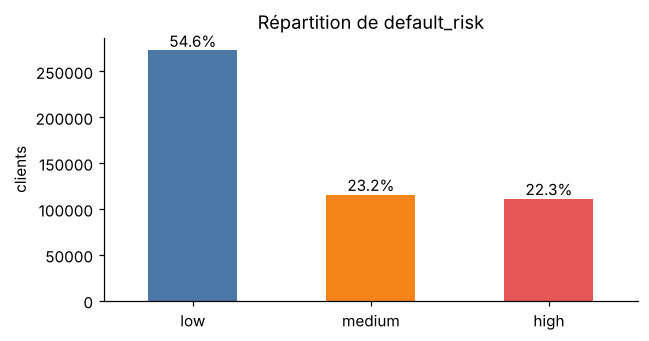

Cible binaire : high = 1 (impayé), low/medium = 0  ->  taux d'impayés = 22.3%


In [5]:
counts = df["default_risk"].value_counts()
fig, ax = plt.subplots(figsize=(6, 3.2))
counts.plot.bar(ax=ax, color=["#4C78A8", "#F58518", "#E45756"])
ax.set_title("Répartition de default_risk"); ax.set_xlabel(""); ax.set_ylabel("clients"); ax.tick_params(axis="x", rotation=0)
for i, v in enumerate(counts): ax.text(i, v, f"{v/len(df):.1%}", ha="center", va="bottom")
plt.tight_layout(); plt.show()
y = encode_target(df["default_risk"], p["data"]["positive_labels"])
print(f"Cible binaire : high = 1 (impayé), low/medium = 0  ->  taux d'impayés = {y.mean():.1%}")

## 3. Variables explicatives selon le risque

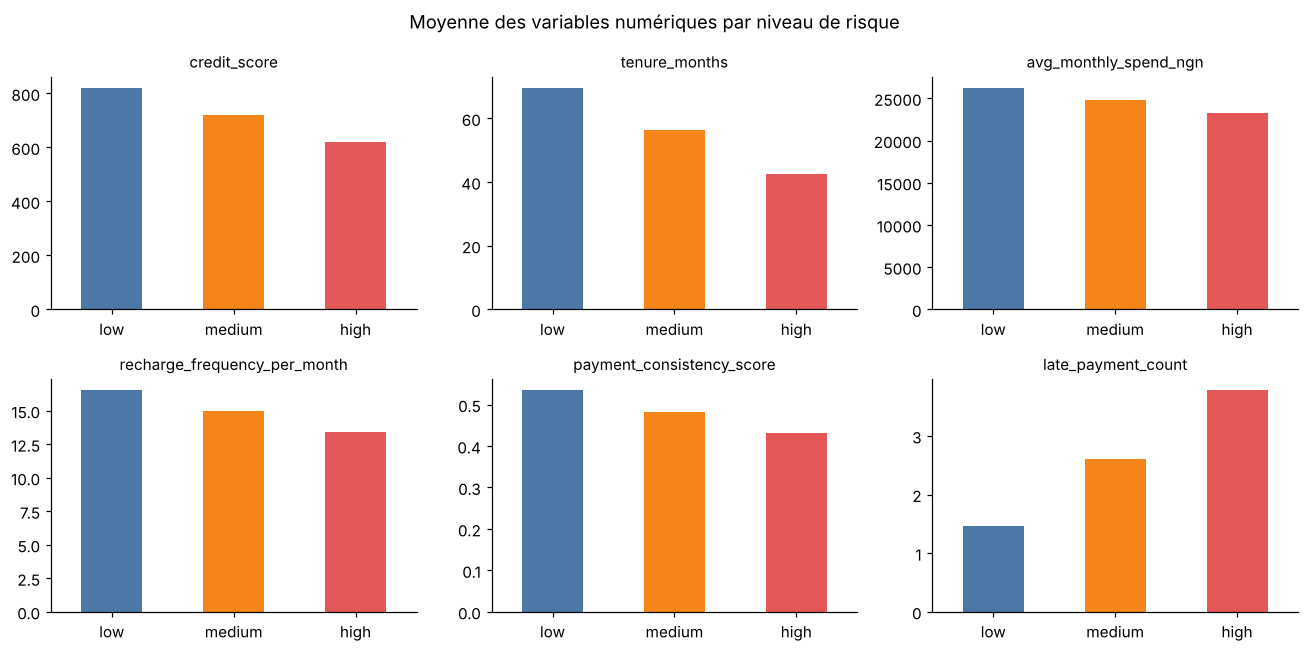

In [6]:
num = ["credit_score", "tenure_months", "avg_monthly_spend_ngn", "recharge_frequency_per_month",
       "payment_consistency_score", "late_payment_count"]
order = ["low", "medium", "high"]
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, col in zip(axes.ravel(), num):
    df.groupby("default_risk")[col].mean().reindex(order).plot.bar(ax=ax, color=["#4C78A8", "#F58518", "#E45756"])
    ax.set_title(col, fontsize=10); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=0)
fig.suptitle("Moyenne des variables numériques par niveau de risque")
plt.tight_layout(); plt.show()

In [7]:
cat = ["operator", "credit_rating", "account_type", "loan_eligibility"]
pd.concat({col: pd.crosstab(df[col], df["default_risk"], normalize="index")[order].round(3) for col in cat})

default_risk                  low  medium   high
operator         9mobile    0.549   0.229  0.222
                 Airtel     0.543   0.232  0.225
                 Glo        0.548   0.231  0.221
                 MTN        0.546   0.232  0.222
credit_rating    excellent  0.701   0.200  0.099
                 fair       0.202   0.300  0.499
                 good       0.701   0.201  0.099
                 poor       0.203   0.302  0.495
account_type     postpaid   0.548   0.232  0.221
                 prepaid    0.545   0.232  0.223
loan_eligibility False      0.202   0.301  0.497
                 True       0.701   0.200  0.099

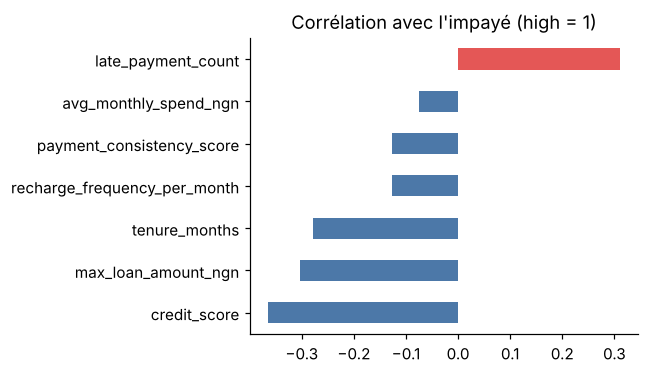

In [8]:
corr = df[num + ["max_loan_amount_ngn"]].assign(impaye=y).corr()["impaye"].drop("impaye").sort_values()
fig, ax = plt.subplots(figsize=(6, 3.5))
corr.plot.barh(ax=ax, color=np.where(corr > 0, "#E45756", "#4C78A8"))
ax.set_title("Corrélation avec l'impayé (high = 1)"); plt.tight_layout(); plt.show()

## 4. Prétraitements retenus

- **Cible** : `high` → 1 (impayé), `low` et `medium` → 0 (`params.yaml > data.positive_labels`).
- **Colonnes retirées** : `customer_id` et `phone_number` (identifiants personnels, sans valeur prédictive), `assessment_date` (valeur unique sur tout le jeu).
- **Numériques** : imputation par la médiane. **Catégorielles** (`operator`, `credit_rating`, `account_type`, `loan_eligibility`) : imputation par la modalité la plus fréquente puis encodage one-hot.
- **Découpage** : 80 % entraînement / 20 % test, stratifié, graine 42.
- **Modèle** : `HistGradientBoostingClassifier` avec pondération des classes (déséquilibre 22 % / 78 %).

## 5. Entraînement et évaluation

In [9]:
res = train(df, p, track=False, out_dir="/tmp/notebook_models")
m = res["metrics"]
pd.Series({k: round(v, 3) for k, v in m.items() if k != "confusion_matrix"}, name="jeu de test (100 000 lignes)").to_frame()

,jeu de test (100 000 lignes)
precision,0.496
recall,0.697
f1,0.580
auc,0.746


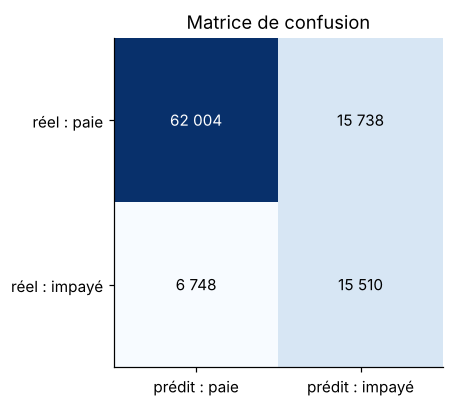

Gate de validation : réussie {'min_f1': 0.55, 'min_auc': 0.72}


In [10]:
cm = np.array(m["confusion_matrix"])
fig, ax = plt.subplots(figsize=(4.6, 3.8))
ax.imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, f"{v:,}".replace(",", " "), ha="center", va="center", color="white" if v > cm.max() / 2 else "black")
ax.set_xticks([0, 1], ["prédit : paie", "prédit : impayé"]); ax.set_yticks([0, 1], ["réel : paie", "réel : impayé"])
ax.set_title("Matrice de confusion"); plt.tight_layout(); plt.show()
print("Gate de validation :", "réussie" if res["passed"] else "échouée", p["gate"])

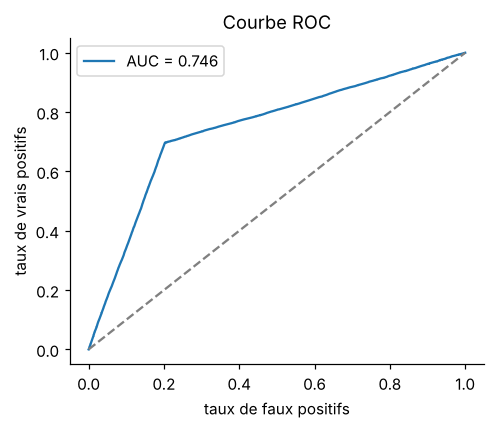

In [11]:
import joblib
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve
pipe = joblib.load("/tmp/notebook_models/model.joblib")
X = df.drop(columns=p["data"]["drop_columns"] + [p["data"]["target"]])
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=p["data"]["test_size"], stratify=y, random_state=p["data"]["seed"])
fpr, tpr, _ = roc_curve(yte, pipe.predict_proba(Xte)[:, 1])
fig, ax = plt.subplots(figsize=(4.6, 4))
ax.plot(fpr, tpr, label=f"AUC = {m['auc']:.3f}"); ax.plot([0, 1], [0, 1], "--", color="grey")
ax.set_xlabel("taux de faux positifs"); ax.set_ylabel("taux de vrais positifs"); ax.set_title("Courbe ROC"); ax.legend()
plt.tight_layout(); plt.show()

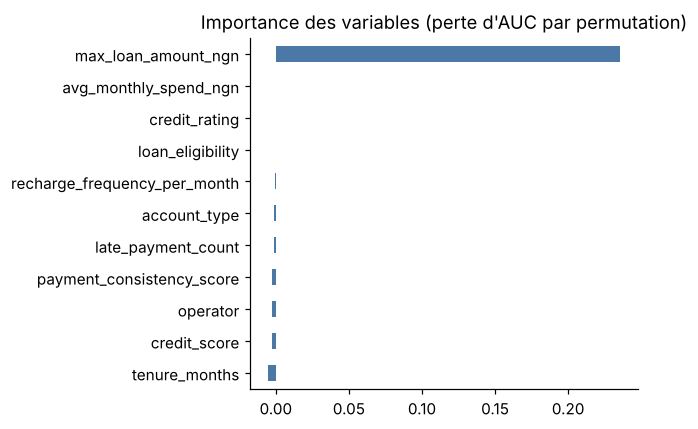

In [12]:
from sklearn.inspection import permutation_importance
s = Xte.sample(5000, random_state=0)
imp = permutation_importance(pipe, s, yte.loc[s.index], scoring="roc_auc", n_repeats=3, random_state=0, n_jobs=-1)
imp = pd.Series(imp.importances_mean, index=s.columns).sort_values()
fig, ax = plt.subplots(figsize=(6, 4))
imp.plot.barh(ax=ax, color="#4C78A8"); ax.set_title("Importance des variables (perte d'AUC par permutation)")
plt.tight_layout(); plt.show()

## 6. Contrôle de non-fuite de données

In [13]:
import copy
q = copy.deepcopy(p)
q["data"]["drop_columns"] += ["credit_score", "credit_rating", "loan_eligibility", "max_loan_amount_ngn"]
r2 = train(df, q, track=False, out_dir="/tmp/notebook_models_sans")
pd.DataFrame({"toutes les variables": {k: round(m[k], 3) for k in ("f1", "auc")},
              "sans variables de score": {k: round(r2["metrics"][k], 3) for k in ("f1", "auc")}})

,toutes les variables,sans variables de score
f1,0.580,0.564
auc,0.746,0.746


## 7. Dérive des données (référence vs. échantillon décalé)

In [14]:
from src.monitoring.drift import drift_report
ref = Xtr.sample(5000, random_state=1)
cur = Xte.sample(5000, random_state=2)
shifted = cur.assign(avg_monthly_spend_ngn=cur["avg_monthly_spend_ngn"] * 1.5)
pd.DataFrame({"production simulée (stable)": drift_report(ref, cur)["psi"],
              "dépense mensuelle x 1,5": drift_report(ref, shifted)["psi"]}).round(3)

,production simulée (stable),"dépense mensuelle x 1,5"
credit_score,0.006,0.006
tenure_months,0.004,0.004
avg_monthly_spend_ngn,0.003,0.558
recharge_frequency_per_month,0.006,0.006
payment_consistency_score,0.005,0.005
late_payment_count,0.002,0.002
max_loan_amount_ngn,0.000,0.000


## 8. Synthèse

- 500 000 clients, aucune valeur manquante ni doublon ; 22,3 % d'impayés (`high`).
- Les impayés ont un score de crédit, une ancienneté et une régularité de paiement plus faibles, et davantage de retards de paiement ; l'opérateur et le type de compte n'ont pas d'effet.
- Le modèle obtient F1 = 0,58 et AUC = 0,75 sur 100 000 clients de test et franchit la gate (F1 ≥ 0,55, AUC ≥ 0,72).
- Les variables de score (`credit_score`, `credit_rating`, `loan_eligibility`, `max_loan_amount_ngn`) sont redondantes : retirées ensemble, l'AUC reste 0,746, ce qui écarte une fuite de données.
- Le PSI détecte une dérive simulée sur la dépense mensuelle (0,56 > 0,2) et reste proche de 0 sur des données stables.